**Data Cleaning & Exploratory Analysis Exercise**

**Import the Required Libraries**

The first step is to import the necessary Python libraries. Pandas is used for data manipulation and analysis, NumPy for numerical operations, Matplotlib for data visualisation, and Seaborn for statistical charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the Dataset**

The dataset is loaded into a Pandas DataFrame named df. This allows us to access, inspect, clean, and analyse the employee records.

In [3]:
df = pd.read_csv("employee_data_messy.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


**Inspect the Dataset**

In [4]:
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (31, 8)


,EmployeeID,Name,Department,Salary,JoinDate,Age,Email,PerformanceScore
0,101,John Smith,Sales,55000,2019-03-15,34.0,john.smith@company.com,4.2
1,102,Maria Garcia,Marketing,62000,03/22/2020,29.0,maria.garcia@company.com,3.8
2,103,David Lee,IT,71000,2018-11-02,NaN,david.lee@company.com,4.5
3,104,Sarah Johnson,sales,58000,2021-01-10,41.0,sarah.johnson@company.com,3.9
4,105,Michael Brown,IT,NaN,2020-07-19,37.0,michael.brown@company.com,4.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   EmployeeID        31 non-null     int64  
 1   Name              31 non-null     object 
 2   Department        31 non-null     object 
 3   Salary            28 non-null     object 
 4   JoinDate          30 non-null     object 
 5   Age               25 non-null     float64
 6   Email             31 non-null     object 
 7   PerformanceScore  28 non-null     float64
dtypes: float64(2), int64(1), object(5)
memory usage: 2.1+ KB


**Check for Missing Values**

In [5]:
print(df.isnull().sum())

EmployeeID          0
Name                0
Department          0
Salary              3
JoinDate            1
Age                 6
Email               0
PerformanceScore    3
dtype: int64


**Standardize the JoinDate Column**

The JoinDate column contains dates in different formats. These dates are converted into a consistent YYYY-MM-DD format to ensure uniformity and support accurate date-based analysis.

In [6]:
df["JoinDate"] = pd.to_datetime(
    df["JoinDate"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
).dt.strftime("%Y-%m-%d")

In [7]:
display(df[["JoinDate"]].head(10))

,JoinDate
0,2019-03-15
1,2020-03-22
2,2018-11-02
3,2021-01-10
4,2020-07-19
5,2019-05-19
6,2019-03-15
7,2020-09-30
8,2017-06-25
9,2021-02-14


**Standardize Department and Email Casing**

The Department column is converted to title case, while the Email column is converted to lowercase. This ensures consistent text formatting and makes records easier to group and compare.

In [8]:
df["Department"] = df["Department"].str.title()
df["Email"] = df["Email"].str.lower()

In [9]:
print(df["Department"].unique())
display(df[["Email"]].head())

['Sales' 'Marketing' 'It' 'Hr']


,Email
0,john.smith@company.com
1,maria.garcia@company.com
2,david.lee@company.com
3,sarah.johnson@company.com
4,michael.brown@company.com


**Trim Whitespace**

In [10]:
# Remove leading and trailing whitespace from column names
df.columns = df.columns.str.strip()

# Remove whitespace from text fields
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Remove whitespace from numeric fields stored as text
for col in ["Salary", "Age", "PerformanceScore"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [11]:
display(df.head())
df.info()

,EmployeeID,Name,Department,Salary,JoinDate,Age,Email,PerformanceScore
0,101,John Smith,Sales,55000.0,2019-03-15,34.0,john.smith@company.com,4.2
1,102,Maria Garcia,Marketing,62000.0,2020-03-22,29.0,maria.garcia@company.com,3.8
2,103,David Lee,It,71000.0,2018-11-02,NaN,david.lee@company.com,4.5
3,104,Sarah Johnson,Sales,58000.0,2021-01-10,41.0,sarah.johnson@company.com,3.9
4,105,Michael Brown,It,NaN,2020-07-19,37.0,michael.brown@company.com,4.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   EmployeeID        31 non-null     int64  
 1   Name              31 non-null     object 
 2   Department        31 non-null     object 
 3   Salary            27 non-null     float64
 4   JoinDate          30 non-null     object 
 5   Age               25 non-null     float64
 6   Email             31 non-null     object 
 7   PerformanceScore  28 non-null     float64
dtypes: float64(3), int64(1), object(4)
memory usage: 2.1+ KB


**Identify and Remove Exact Duplicate Rows**

In [12]:
# Count exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates()

# Verify the result
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 1
Dataset shape after removing duplicates: (30, 8)


**Handle Missing Values**

In [13]:
# Check missing values
print(df[["Salary", "Age", "PerformanceScore"]].isnull().sum())

Salary              4
Age                 6
PerformanceScore    3
dtype: int64


**Identify invalid values**

In [14]:
# Identify invalid salary and age values
print("Negative salaries:", (df["Salary"] < 0).sum())
print("Ages above 100:", (df["Age"] > 100).sum())

# Identify performance scores outside the allowed range
print(
    "Invalid performance scores:",
    ((df["PerformanceScore"] < 1) |
     (df["PerformanceScore"] > 5)).sum()
)

Negative salaries: 1
Ages above 100: 2
Invalid performance scores: 0


**Replace invalid values and fill missing values**

In [15]:
# Replace invalid values with missing values
df.loc[df["Salary"] < 0, "Salary"] = np.nan
df.loc[df["Age"] > 100, "Age"] = np.nan

df.loc[
    ~df["PerformanceScore"].between(1, 5),
    "PerformanceScore"
] = np.nan

# Fill missing values using the median
for col in ["Salary", "Age", "PerformanceScore"]:
    df[col] = df[col].fillna(df[col].median())

# Verify the result
print(df[["Salary", "Age", "PerformanceScore"]].isnull().sum())

Salary              0
Age                 0
PerformanceScore    0
dtype: int64


**Validate Email Addresses**

Email addresses are checked to identify incomplete or malformed entries. Invalid addresses are flagged for review to improve data quality and ensure that employee contact information follows a consistent format.

In [16]:
# Define a basic email validation pattern
email_pattern = r'^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$'

# Identify invalid or missing email addresses
df["EmailValid"] = df["Email"].str.match(
    email_pattern, na=False
)

# Display invalid email addresses
invalid_emails = df.loc[
    ~df["EmailValid"], ["EmployeeID", "Name", "Email"]
]

display(invalid_emails)

print("Number of invalid emails:", len(invalid_emails))

,EmployeeID,Name,Email
10,111,Patricia Anderson,patricia.anderson@


Number of invalid emails: 1


**Calculate the Average Salary per Department**

The average salary is calculated for each department to compare employee compensation across the organisation. This helps identify departments with higher or lower average salaries.

In [18]:
average_salary = df.groupby("Department")["Salary"].mean()

print("Average Salary per Department:")
display(average_salary.reset_index())

Average Salary per Department:


,Department,Salary
0,Hr,51250.000000
1,It,69000.000000
2,Marketing,62083.333333
3,Sales,57666.666667


**Visualise the Results**

A bar chart is created to compare average salaries across departments visually, making differences in employee compensation easier to identify.

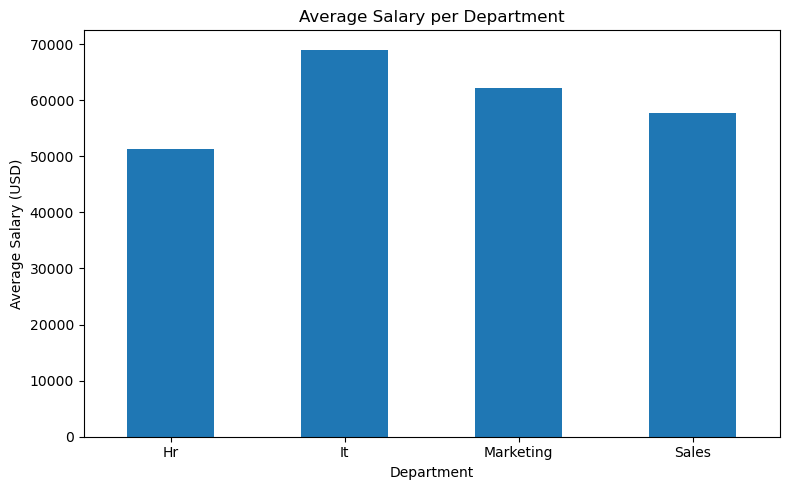

In [25]:
average_salary.plot(kind="bar", figsize=(8, 5))

plt.title("Average Salary per Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The bar chart shows that IT has the highest average salary, at approximately $69,000, while HR has the lowest, at approximately $51,000. Marketing and Sales have average salaries of approximately $62,000 and $58,000, respectively. This indicates differences in average employee compensation across departments.

**Identify the Department with the Highest Average Performance Score**

In [26]:
average_performance = (
    df.groupby("Department")["PerformanceScore"].mean()
)

print("Average Performance Score per Department:")
display(average_performance.reset_index())

print(
    "Department with the highest average performance:",
    average_performance.idxmax()
)

Average Performance Score per Department:


,Department,PerformanceScore
0,Hr,3.466667
1,It,4.311111
2,Marketing,3.750000
3,Sales,3.888889


Department with the highest average performance: It


**Visualise the results**

A bar chart is used to compare average performance scores across departments and identify differences in employee performance.

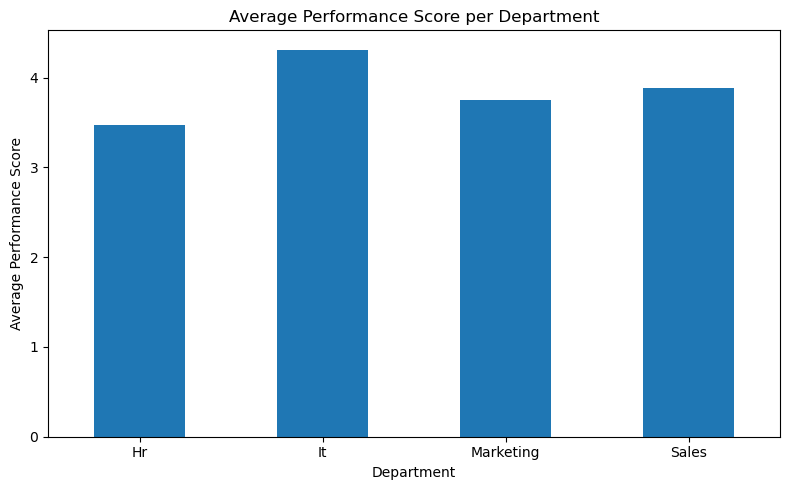

In [21]:
average_performance.plot(kind="bar", figsize=(8, 5))

plt.title("Average Performance Score per Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The bar chart shows that IT has the highest average performance score, at approximately 4.31 out of 5, while HR has the lowest, at approximately 3.47. Marketing and Sales have average scores of approximately 3.75 and 3.89, respectively. This indicates differences in average employee performance across departments.

**Examine the Relationship Between Age and Performance Score**

In [22]:
# Calculate the correlation coefficient
correlation = df["Age"].corr(df["PerformanceScore"])

print("Correlation coefficient:", round(correlation, 3))

Correlation coefficient: 0.459


**Visualise the relationship**

A scatter plot is created to visualise the relationship between employee age and performance score. Each point represents an employee.

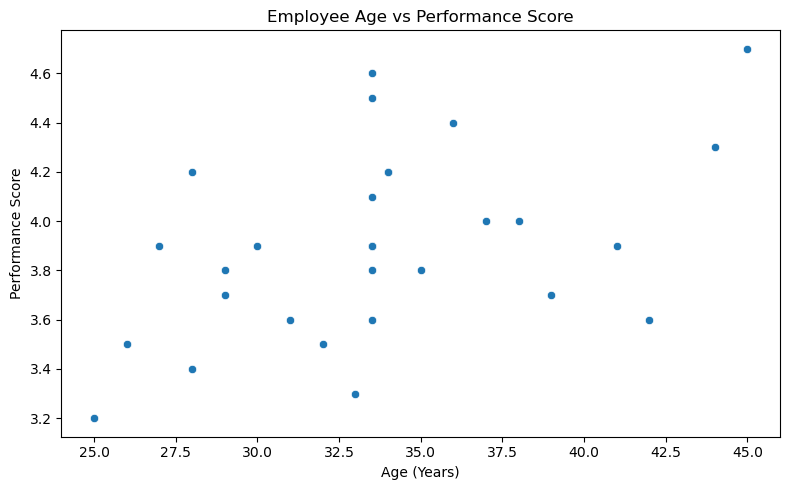

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="PerformanceScore"
)

plt.title("Employee Age vs Performance Score")
plt.xlabel("Age (Years)")
plt.ylabel("Performance Score")
plt.tight_layout()
plt.show()

The scatter plot shows a generally positive relationship between employee age and performance score, although the points are widely distributed. This suggests that older employees tend to have higher performance scores in some cases, but the relationship is not consistent for every employee. Further analysis is required to determine the strength of this relationship.

**Calculate the Number of Employees Who Joined Each Year**

The standardized joining dates are converted into datetime format, and the year is extracted from each valid date. The employees are then counted by joining year and displayed in chronological order.

In [28]:
# Convert JoinDate to datetime format
df["JoinDate"] = pd.to_datetime(
    df["JoinDate"],
    errors="coerce"
)

# Extract the joining year and count employees
employees_per_year = (
    df["JoinDate"]
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

# Display the results
print("Number of Employees Who Joined Each Year:")

display(pd.DataFrame({
    "Year": employees_per_year.index,
    "Number of Employees": employees_per_year.values
}))

Number of Employees Who Joined Each Year:


,Year,Number of Employees
0,2017,2
1,2018,4
2,2019,8
3,2020,7
4,2021,5
5,2022,3


**Visualise the results**

A bar chart is used to display the number of employees who joined the company each year. This makes it easier to compare annual hiring levels and identify years with higher or lower employee recruitment.

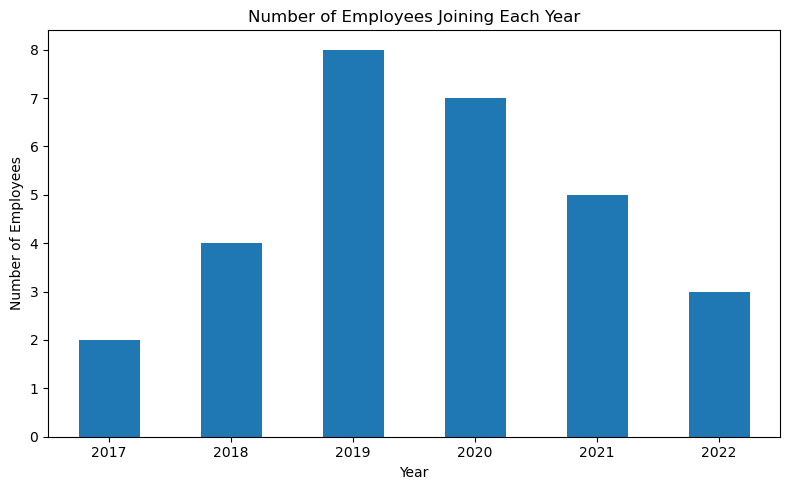

In [29]:
employees_per_year.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of Employees Joining Each Year")
plt.xlabel("Year")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The bar chart illustrates the number of employees who joined the company in each year. The year with the tallest bar had the highest number of new employees, while the shortest bar represents the lowest number of new employees. This provides an overview of the company's annual hiring patterns.

**Identify the Three Highest-Paid Employees**

The cleaned dataset is sorted by salary in descending order to identify the three highest-paid employees. Their employee IDs, names, departments, and annual salaries are displayed for comparison.

In [30]:
# Select the three employees with the highest salaries
top_3_employees = (
    df.nlargest(3, "Salary")
    [["EmployeeID", "Name", "Department", "Salary"]]
)

# Display the results
print("Top 3 Highest-Paid Employees:")
display(top_3_employees)

Top 3 Highest-Paid Employees:


,EmployeeID,Name,Department,Salary
26,126,Joshua King,It,74000.0
8,109,Linda Martinez,It,73000.0
15,116,Paul Martin,It,72000.0


The table presents the three highest-paid employees in the cleaned dataset, showing their employee IDs, names, departments, and annual salaries. It identifies the employees with the highest salary values among the records analysed.

**Check for Missing Values and crosschecking**

In [31]:
print(df.isnull().sum())

EmployeeID          0
Name                0
Department          0
Salary              0
JoinDate            1
Age                 0
Email               0
PerformanceScore    0
EmailValid          0
dtype: int64


In [32]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [33]:
print("Negative salaries:", (df["Salary"] < 0).sum())
print("Unrealistic ages:", (df["Age"] > 100).sum())

print(
    "Invalid performance scores:",
    (~df["PerformanceScore"].between(1, 5)).sum()
)

Negative salaries: 0
Unrealistic ages: 0
Invalid performance scores: 0


In [34]:
print("Invalid emails:", (~df["EmailValid"]).sum())

Invalid emails: 1


In [37]:
display(
    df.loc[~df["EmailValid"], ["EmployeeID", "Name", "Email"]]
)

,EmployeeID,Name,Email
10,111,Patricia Anderson,patricia.anderson@


**One malformed email address was identified during validation. The address belonging to Patricia Anderson is incomplete, as it lacks a domain name. It was retained in the dataset and flagged for review rather than being modified without verification.**

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 30
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   EmployeeID        30 non-null     int64         
 1   Name              30 non-null     object        
 2   Department        30 non-null     object        
 3   Salary            30 non-null     float64       
 4   JoinDate          29 non-null     datetime64[ns]
 5   Age               30 non-null     float64       
 6   Email             30 non-null     object        
 7   PerformanceScore  30 non-null     float64       
 8   EmailValid        30 non-null     bool          
dtypes: bool(1), datetime64[ns](1), float64(3), int64(1), object(3)
memory usage: 2.1+ KB


In [36]:
import os

print("File exists:", os.path.exists("employee_data_cleaned.csv"))

File exists: False


In [38]:
import os

print("Current folder:", os.getcwd())

df.to_csv("employee_data_cleaned.csv", index=False)

print(
    "File exists:",
    os.path.exists("employee_data_cleaned.csv")
)

Current folder: C:\Users\USER\Documents\HerTechTrail Academy\Data Analysis Cohort 16\CAPSTONE PROJECT
File exists: True


**Correct the department labels**

In [39]:
df["Department"] = df["Department"].replace({
    "Hr": "HR",
    "It": "IT"
})

In [40]:
print(df["Department"].unique())

['Sales' 'Marketing' 'IT' 'HR']


**Verify the top three salaries**

In [41]:
# Reload the original dataset
original_df = pd.read_csv("employee_data_messy.csv")

# Convert original salary values to numeric
original_df["Salary"] = pd.to_numeric(
    original_df["Salary"].astype(str).str.strip(),
    errors="coerce"
)

# Keep only valid, non-negative original salaries
original_df = original_df[original_df["Salary"] >= 0]

# Display the three highest-paid employees
top_3_original = (
    df.merge(
        original_df[["EmployeeID", "Salary"]].rename(
            columns={"Salary": "OriginalSalary"}
        ),
        on="EmployeeID",
        how="left"
    )
)

top_3_original = (
    top_3_original[
        top_3_original["OriginalSalary"].notna()
    ]
    .nlargest(3, "OriginalSalary")
    [["EmployeeID", "Name", "Department", "OriginalSalary"]]
)

display(top_3_original)

,EmployeeID,Name,Department,OriginalSalary
26,126,Joshua King,IT,74000.0
8,109,Linda Martinez,IT,73000.0
15,116,Paul Martin,IT,72000.0


**Save and download the cleaned dataset**

In [43]:
df.to_csv("employee_data_cleaned.csv", index=False)

import os
print("Saved successfully:", os.path.exists("employee_data_cleaned.csv"))
print("File location:", os.path.abspath("employee_data_cleaned.csv"))

Saved successfully: True
File location: C:\Users\USER\Documents\HerTechTrail Academy\Data Analysis Cohort 16\CAPSTONE PROJECT\employee_data_cleaned.csv
